# Inspect the MaMMoS magnetic-SANS data products

This notebook reads one generated HDF5 file through `mammos_entity`, keeping each entity's ontology label, unit, description, and numerical value together. Each file contains one affine magnetization model, its orientation distribution, and the corresponding forward-model results.

| HDF5 group | Stored information |
| --- | --- |
| `model` | Affine coefficients $\mathbf m_0$, $\mathbf m_1$, sphere radius $R$, and orientation density $\psi$. |
| `real_space` | Local body-frame coordinates `x`, `y`, `z` and magnetization components `mx`, `my`, `mz` on a Cartesian grid after the sphere cut. |
| `detector` | Shared detector coordinates $(q,\theta)$ and $(q_y,q_z)$, together with the one-dimensional axes. |
| `average_magnetization` | Orientation-averaged real-space magnetization and the combined orientation- and volume-averaged magnetization, evaluated by QMC and, where available, analytically. |

The reciprocal-space results follow the forward chain

$$
\left\langle\widetilde{\boldsymbol\Gamma}\right\rangle_\psi
\xrightarrow{\boldsymbol\Pi_\perp}
\left\langle\widetilde{\mathbf G}\right\rangle_\psi
\xrightarrow{\mathcal C}
I_{\mathrm M}.
$$

These stages are stored in `average_gamma_tensor`, `average_G_tensor`, and `SANS_cross_sections`, respectively, with two parallel evaluation branches:

- **QMC (`qmc`):** The orientation-averaged $\Gamma$ tensor is estimated using a Sobol sequence of rotations weighted by $\psi$. Its transverse projection gives $G$, from which the basic and derived SANS cross sections are computed.
- **Analytical (`analytical`, where available):** Closed-form expressions provide the corresponding reference results. For cases admitting the joint $\mathrm{SO}(3)$-covariant representation, the three radial spectra $\Gamma_\perp(q)$, $\Gamma_\parallel(q)$, and $\Gamma_\times(q)$ are additionally stored in `average_gamma_tensor/analytical/spectra`. They describe the full averaged $\Gamma$ tensor; only $\Gamma_\perp$ and $\Gamma_\times$ enter the projected $G$ tensor and the purely magnetic SANS cross sections.

Both branches store all nine complex tensor components on the same detector points, together with the basic and derived SANS channels, so numerical and analytical results can be compared directly.

The modules `python.case_studies.case_study1` and `python.case_studies.case_study2` generate the model files in `output/data/`. Launch this notebook with `pixi run notebook` from the repository root and select the HDF5 file using `path` below.

In [1]:
from pathlib import Path

import mammos_entity as me
import matplotlib.pyplot as plt
import numpy as np

path = Path.cwd() / "output/data/case_study2_1.h5"

# Read data using mammos-entity

In [2]:
data = me.from_hdf5(path)

for name, item in data:
    print(name)

SANS_cross_sections
average_G_tensor
average_gamma_tensor
average_magnetization
detector
model
real_space


# Inspect the properties of the model

In [3]:
for name, item in data["model"]:
    print(name)
    print("  ", data["model"][name])

m0
   ISQDimensionlessQuantity(value=[0.5       0.        0.8660254], description='Constant local magnetization vector; shape (3,).')
m1
   ISQDimensionlessQuantity(value=
[[ 0. -7.  0.]
 [ 7.  0.  0.]
 [ 0.  0.  0.]],
 description='Local magnetization gradient matrix; shape (3, 3).')
R
   ISQDimensionlessQuantity(value=1.0, description='Sphere radius in dimensionless model coordinates.')
psi
   EntityCollection(
    description='Orientation density relative to the normalized SO(3) Haar measure.',
    name='uniform',
)


# Inspect the real-space data

In [4]:
for name, item in data["real_space"]:
    print(name, type(item))

x <class 'mammos_entity._entity.Entity'>
y <class 'mammos_entity._entity.Entity'>
z <class 'mammos_entity._entity.Entity'>
mx <class 'mammos_entity._entity.Entity'>
my <class 'mammos_entity._entity.Entity'>
mz <class 'mammos_entity._entity.Entity'>


In [5]:
import pyvista as pv

r = data["real_space"]
points = np.column_stack([r[c].value for c in ("x", "y", "z")])
M = np.column_stack([r[c].value for c in ("mx", "my", "mz")])

field = pv.PolyData(points)
field["M"] = M

norm = np.linalg.norm(M, axis=1)
field["Mz/|M|"] = np.divide(
    M[:, 2],
    norm,
    out=np.zeros_like(norm),
    where=norm > 0,
)

arrow = pv.Arrow(start=(-0.5, 0, 0), scale=1.0)

arrows = field.glyph(
    orient="M",
    scale=False,
    factor=0.15 * data["model"]["R"].value,
    geom=arrow,
)
arrows.plot(
    scalars="Mz/|M|",
    cmap="RdBu",
    clim=(-1, 1),
    background="white",
    jupyter_backend="client",
)


Widget(value='<iframe src="http://localhost:53087/index.html?ui=P_0x13fed11d0_0&reconnect=auto" class="pyvista…

# inspect the detector coordinates

In [6]:
for name, item in data["detector"]:
    print(name, type(item))

q_axis <class 'mammos_entity._entity.Entity'>
theta_axis <class 'mammos_entity._entity.Entity'>
q <class 'mammos_entity._entity.Entity'>
theta <class 'mammos_entity._entity.Entity'>
qy <class 'mammos_entity._entity.Entity'>
qz <class 'mammos_entity._entity.Entity'>


In [7]:
q = data["detector"]["q_axis"]
print(q)

ISQDimensionlessQuantity(value=
[0.05       0.12857143 0.20714286 0.28571429 0.36428571 0.44285714
 0.52142857 0.6        0.67857143 0.75714286 0.83571429 0.91428571
 0.99285714 1.07142857 1.15       1.22857143 1.30714286 1.38571429
 1.46428571 1.54285714 1.62142857 1.7        1.77857143 1.85714286
 1.93571429 2.01428571 2.09285714 2.17142857 2.25       2.32857143
 2.40714286 2.48571429 2.56428571 2.64285714 2.72142857 2.8
 2.87857143 2.95714286 3.03571429 3.11428571 3.19285714 3.27142857
 3.35       3.42857143 3.50714286 3.58571429 3.66428571 3.74285714
 3.82142857 3.9        3.97857143 4.05714286 4.13571429 4.21428571
 4.29285714 4.37142857 4.45       4.52857143 4.60714286 4.68571429
 4.76428571 4.84285714 4.92142857 5.        ],
 description='Detector q_axis in dimensionless model coordinates.')


In [8]:
qz = data["detector"]["qz"]
qy = data["detector"]["qy"]

# Inspect and vizualize the Fourier-space correlation tensor

In [9]:
gamma = data["average_gamma_tensor"]
for name, item in gamma:
    print(name)
    for name1, item1 in gamma[name]:
        print("  ", name1)

qmc
   xx
   xy
   xz
   yx
   yy
   yz
   zx
   zy
   zz
analytical
   xx
   xy
   xz
   yx
   yy
   yz
   zx
   zy
   zz
   spectra


# Inspect the analytical spectra

In [10]:
gamma_spec = gamma["analytical"]["spectra"]
for name, item in gamma_spec:
    print(name, type(item))

perpendicular <class 'mammos_entity._entity.Entity'>
parallel <class 'mammos_entity._entity.Entity'>
cross <class 'mammos_entity._entity.Entity'>


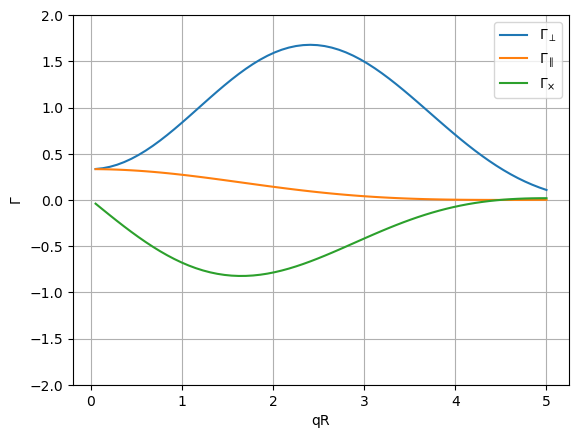

In [11]:
gamma_par = gamma_spec["parallel"]
gamma_perp = gamma_spec["perpendicular"]
gamma_cross = gamma_spec["cross"]
plt.plot(q.value, gamma_perp.value, label=r"$\Gamma_{\perp}$")
plt.plot(q.value, gamma_par.value, label=r"$\Gamma_{\parallel}$")
plt.plot(q.value, gamma_cross.value, label=r"$\Gamma_{\times}$")
plt.grid()
plt.legend()
plt.ylim(-2, 2)
plt.xlabel(r"qR")
plt.ylabel(r"$\Gamma$")
plt.show()

# Inspect and visualize the magnetic SANS data

In [12]:
magSANS_cs = data["SANS_cross_sections"]
for name, item in magSANS_cs:
    print(name)
    for name1, item1 in magSANS_cs[name]:
        print("  ", name1)

parameters
   P
   K
   I_N
   I_NM
qmc
   basic
   derived
analytical
   basic
   derived


In [13]:
magSANS_cs_basic_analytical = magSANS_cs["analytical"]["basic"]
for name, item in magSANS_cs_basic_analytical:
    print(name, type(item))

I_M <class 'mammos_entity._entity.Entity'>
I_P <class 'mammos_entity._entity.Entity'>
I_chi <class 'mammos_entity._entity.Entity'>


In [14]:
I_chi = magSANS_cs_basic_analytical["I_chi"]
print(I_chi)

ISQDimensionlessQuantity(value=
[[ 0.0807944   0.20725782  0.33240782 ... -0.03472109 -0.03680782
  -0.03727952]
 [ 0.08048696  0.20646914  0.33114291 ... -0.03458896 -0.03666776
  -0.03713766]
 [ 0.07956695  0.20410911  0.3273578  ... -0.0341936  -0.03624863
  -0.03671316]
 ...
 [ 0.0780414   0.20019568  0.3210813  ... -0.033538   -0.03555363
  -0.03600925]
 [ 0.07956695  0.20410911  0.3273578  ... -0.0341936  -0.03624863
  -0.03671316]
 [ 0.08048696  0.20646914  0.33114291 ... -0.03458896 -0.03666776
  -0.03713766]],
 description='I_chi on detector/q and detector/theta in normalized model intensity units.')


In [15]:
magSANS_cs_derived_analytical = magSANS_cs["analytical"]["derived"]
for name, item in magSANS_cs_derived_analytical:
    print(name, type(item))

I_sf <class 'mammos_entity._entity.Entity'>
I_pp <class 'mammos_entity._entity.Entity'>
I_mm <class 'mammos_entity._entity.Entity'>
I_pm <class 'mammos_entity._entity.Entity'>
I_mp <class 'mammos_entity._entity.Entity'>
I_plus <class 'mammos_entity._entity.Entity'>
I_minus <class 'mammos_entity._entity.Entity'>
I_unp <class 'mammos_entity._entity.Entity'>


In [16]:
I_sf = magSANS_cs_derived_analytical["I_sf"]
print(I_sf)

ISQDimensionlessQuantity(value=
[[0.6695989  0.68601475 0.7166905  ... 0.3298203  0.26917365 0.21564347]
 [0.66705573 0.68340922 0.71396847 ... 0.32856762 0.26815131 0.21482444]
 [0.65950347 0.67567181 0.70588507 ... 0.32484765 0.26511536 0.21239224]
 ...
 [0.64717159 0.66303761 0.69268592 ... 0.31877341 0.26015804 0.20842078]
 [0.65950347 0.67567181 0.70588507 ... 0.32484765 0.26511536 0.21239224]
 [0.66705573 0.68340922 0.71396847 ... 0.32856762 0.26815131 0.21482444]],
 description='I_sf on detector/q and detector/theta in normalized model intensity units.')


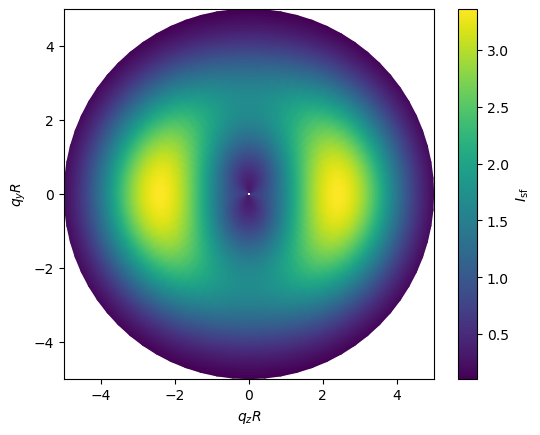

In [17]:
qz_plot = np.concatenate([qz.q, qz.q[:1]], axis=0)
qy_plot = np.concatenate([qy.q, qy.q[:1]], axis=0)
I_sf_plot = np.concatenate([I_sf.q, I_sf.q[:1]], axis=0)

fig, ax = plt.subplots()
mesh = ax.pcolormesh(
    qz_plot,
    qy_plot,
    I_sf_plot,
    shading="gouraud",
)
fig.colorbar(mesh, ax=ax, label=r"$I_{\mathrm{sf}}$")
ax.set(xlabel=r"$q_zR$", ylabel=r"$q_yR$", aspect="equal")
plt.show()

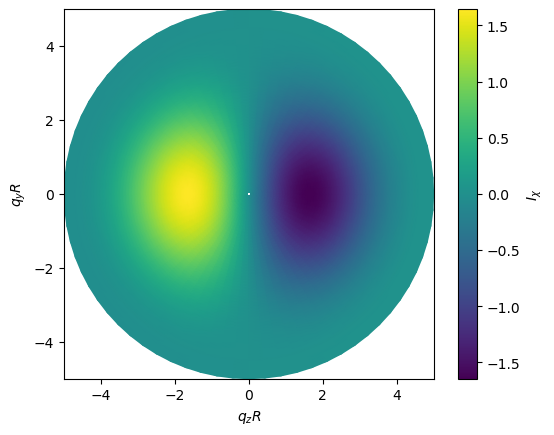

In [18]:
qz_plot = np.concatenate([qz.q, qz.q[:1]], axis=0)
qy_plot = np.concatenate([qy.q, qy.q[:1]], axis=0)
I_chi_plot = np.concatenate([I_chi.q, I_chi.q[:1]], axis=0)

fig, ax = plt.subplots()
mesh = ax.pcolormesh(
    qz_plot,
    qy_plot,
    I_chi_plot,
    shading="gouraud",
)
fig.colorbar(mesh, ax=ax, label=r"$I_{\chi}$")
ax.set(xlabel=r"$q_zR$", ylabel=r"$q_yR$", aspect="equal")
plt.show()